# 22b — Week 6 (supplementary): quantum kernel ridge regression and its controls, validation only

Supplementary item of the Week 5 plan ("quantum kernel ridge regression on a small subsample"), started after all main
Week 5 items were done. Model code: `src/models/qkernel.py`.

* **Input:** the networks' 60-minute window with local scaling (k = 1..59), reduced by PCA (fitted on the training
  subsample only) to n components, whitened: z(t) in R^n, n = number of qubits.
* **Kernels:** `qk` = fidelity kernel |<psi(z)|psi(z')>|^2 of an IQP-type feature map (2 layers of H, RZ(2 a z_i),
  IsingZZ(2 a^2 z_i z_j) on ring pairs; exact statevectors); `qk_noent` = the same map without IsingZZ (product state,
  classical closed form); `rbf` = Gaussian kernel exp(-gamma ||z - z'||^2), gamma = a^2 / 2 (matched bandwidth grid).
* **Readout:** kernel ridge per horizon on (P(t + h) - P(t)) / s; one eigendecomposition per kernel gives all penalties
  (same penalty grid as the QRC readout). Bandwidth a in {0.01, 0.03, 0.1, 0.3, 1} chosen on validation (the near-linear end is included because the QRC screen chose its smallest scale) (mean MAE over horizons),
  penalty per horizon on validation. The kernels are deterministic: one run per configuration (no seeds).
* **Training subsamples:** the most recent 1% block of train origins (1,967 origins, the 1% point of notebook 21) and
  the most recent 5% block thinned to every second origin (about 4,900; a full 5% Gram matrix of about 9,800^2 is too
  large for 8 GB RAM). Qubits n = 4 and 8.
* **Comparison:** the notebook-21 models at the 1% fraction (same block), Diebold-Mariano with Holm correction, and a
  kernel-concentration diagnostic (variance of off-diagonal kernel values versus qubits).

Provisional decisions by the assistant; every configuration tried is logged (`reports/week5/quantum_variants_log.csv`).
The circuits are classically simulable; no claim of quantum advantage is made. **The test split is not used.**

In [1]:
# Cell 1: setup
import sys, json, time, math, shutil, warnings, traceback
from pathlib import Path
import numpy as np
import polars as pl
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import pennylane as qml
from models import rnn as R
from models import qkernel as QK
from models import week6 as W
from evaluation import compare as C

GROUP = "week6_qkernel"
FR_GROUP = "week6_fraction"
REP = ROOT / "reports" / "week6"
FIG = ROOT / "reports" / "figures" / "week6"
REP.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
DATASET = "data/processed/model_dataset.parquet"
DATA_CFG = {"scaling": "local", "calendar": False, "covariates": False}
KINDS = ["qk", "qk_noent", "rbf"]
QUBITS = (4, 8)
SUBS = [(0.01, 1), (0.05, 2)]          # (fraction of the most recent train block, keep every k-th origin)
TRACKING = "auto"
SUMMARY = {"kinds": KINDS, "qubits": QUBITS, "subsamples": SUBS, "scales": QK.SCALES, "ridge_grid": QK.RIDGE_GRID,
           "n_layers": QK.N_LAYERS}
print("pennylane", qml.__version__, "| kinds", KINDS, "| qubits", QUBITS, "| subsamples", SUBS, "| scales", QK.SCALES)

pennylane 0.45.1 | kinds ['qk', 'qk_noent', 'rbf'] | qubits (4, 8) | subsamples [(0.01, 1), (0.05, 2)] | scales (0.01, 0.03, 0.1, 0.3, 1.0)


In [2]:
# Cell 2: unit checks (no real data)
checks = {}
rng = np.random.default_rng(0)
Z = rng.normal(size=(6, 3))

# (a) broadcast statevectors equal a one-sample circuit; kernel diagonal = 1
S = QK.states(Z, 0.7, entangle=True)
dev = qml.device("default.qubit", wires=3)
@qml.qnode(dev)
def one(z):
    for _ in range(QK.N_LAYERS):
        for i in range(3):
            qml.Hadamard(wires=i); qml.RZ(2 * 0.7 * z[i], wires=i)
        for a, b in QK.pairs(3):
            qml.IsingZZ(2 * 0.7 ** 2 * z[a] * z[b], wires=[a, b])
    return qml.state()
ref = np.array([one(z) for z in Z])
d_a = float(np.abs(ref - S).max())
K = QK.Kernel("qk", 0.7).gram(S, S)
checks["broadcast_equals_single_circuit"] = d_a < 1e-10
checks["fidelity_diag_is_one"] = float(np.abs(np.diag(K) - 1).max()) < 1e-10
print(f"(a) broadcast vs single circuit: max |diff| {d_a:.1e} | diag(K) - 1: {np.abs(np.diag(K) - 1).max():.1e}")

# (b) without entanglement the kernel is the product of one-qubit kernels
kn = QK.Kernel("qk_noent", 0.7)
Kn = kn.gram(kn.embed(Z), kn.embed(Z))
prod = np.ones_like(Kn)
for i in range(3):
    s1 = QK.states(Z[:, [i]], 0.7, entangle=False)
    prod *= np.abs(s1.conj() @ s1.T) ** 2
d_b = float(np.abs(Kn - prod).max())
checks["noent_is_product_kernel"] = d_b < 1e-10
print(f"(b) no-entanglement kernel vs product of one-qubit kernels: max |diff| {d_b:.1e}")

# (c) closed-form kernel ridge equals a direct solve; (d) Gram matrices are PSD
Zt = rng.normal(size=(40, 3)); Y = rng.normal(size=(40, 3))
Kt = QK.Kernel("qk", 0.5).gram(QK.states(Zt, 0.5), QK.states(Zt, 0.5))
A, ym, emin, emax = QK.fit_all(Kt, Y)
r = QK.RIDGE_GRID[6]
direct = np.linalg.solve(Kt + r * 40 * np.eye(40), Y - Y.mean(0))
d_c = float(np.abs(A[6] - direct).max())
checks["kernel_ridge_closed_form"] = d_c < 1e-8
checks["gram_psd"] = emin > -1e-8
# (e) RBF gram equals the direct formula
kr = QK.Kernel("rbf", 0.5)
Kr = kr.gram(Zt, Zt)
direct_r = np.exp(-0.125 * ((Zt[:, None, :] - Zt[None, :, :]) ** 2).sum(-1))
checks["rbf_formula"] = float(np.abs(Kr - direct_r).max()) < 1e-10
print(f"(c) closed form vs solve: {d_c:.1e} | (d) min eigenvalue {emin:.2e} | (e) RBF max diff {np.abs(Kr - direct_r).max():.1e}")
UNIT_OK = all(checks.values())
print(checks, "\nUNIT CHECKS PASSED" if UNIT_OK else "\nUNIT CHECKS FAILED")

(a) broadcast vs single circuit: max |diff| 0.0e+00 | diag(K) - 1: 4.0e-15
(b) no-entanglement kernel vs product of one-qubit kernels: max |diff| 8.9e-16
(c) closed form vs solve: 1.1e-10 | (d) min eigenvalue 2.80e-04 | (e) RBF max diff 2.2e-16
{'broadcast_equals_single_circuit': True, 'fidelity_diag_is_one': True, 'noent_is_product_kernel': True, 'kernel_ridge_closed_form': True, 'gram_psd': True, 'rbf_formula': True} 
UNIT CHECKS PASSED


In [3]:
# Cell 3: DRY RUN on synthetic data (small: 2 and 4 qubits, two bandwidths; deleted afterwards)
def synth(n=30000, seed=0):
    rng = np.random.default_rng(seed)
    t = np.arange(n)
    x = np.zeros(n)
    e = rng.normal(0, 0.4, n)
    for i in range(1, n):
        x[i] = 0.9 * x[i - 1] + e[i]
    P = 30 + np.cumsum(rng.normal(0, 0.01, n)) + x - 0.3 * (t % 5 == 0)
    valid = np.ones(n, bool)
    for g0 in rng.choice(np.arange(500, n - 500), 6, replace=False):
        valid[g0:g0 + 150] = False
    i_tr, i_va = int(0.7 * n), int(0.85 * n)
    split = np.where(t < i_tr, "train", np.where(t < i_va, "val", "test"))
    c = np.concatenate([[0], np.cumsum(~valid)])
    win_ok = np.zeros(n, bool)
    win_ok[R.INPUT_LEN - 1:] = (c[R.INPUT_LEN:] - c[:n - R.INPUT_LEN + 1]) == 0
    Pv = np.where(valid, P, np.nan)
    L24 = pl.Series(Pv).fill_nan(None).rolling_mean(1440, min_samples=720).to_numpy()
    cols = {"minute_epoch": t * 60, "P_kW": Pv, "valid": valid, "split": split, "mod5": (t % 5).astype(np.int64),
            "hour_sin": np.sin(2 * np.pi * (t // 60 % 24) / 24), "hour_cos": np.cos(2 * np.pi * (t // 60 % 24) / 24),
            "L24_kW": L24}
    thr = {}
    for h in R.HORIZONS:
        ok = win_ok.copy()
        ok[n - h:] = False
        ok[:n - h] &= valid[h:]
        sp = np.full(n, None, dtype=object)
        tt = np.arange(n - h)
        sp[:n - h] = np.where(tt + h < i_tr, "train", np.where((tt >= i_tr) & (tt + h < i_va), "val",
                              np.where(tt >= i_va, "test", None)))
        ok &= sp != None  # noqa: E711
        rel = np.full(n, np.nan)
        rel[:n - h] = np.abs(P[h:] - P[:n - h]) / L24[:n - h]
        trm = ok & (sp == "train") & np.isfinite(rel)
        thr[str(h)] = {"rel_p95": float(np.quantile(rel[trm], 0.95))}
        ramp = np.where(ok & np.isfinite(rel), (rel > thr[str(h)]["rel_p95"]).astype(float), np.nan)
        cols[f"ok_h{h}"], cols[f"split_h{h}"], cols[f"ramp_h{h}"] = ok, sp.tolist(), ramp
    df = pl.DataFrame(cols).with_columns(pl.col("P_kW").fill_nan(None), pl.col("L24_kW").fill_nan(None))
    return df, {"thresholds": thr}


def score_runs(md_, meta_, data_, group, kind, n, frac, thin, res, tracking):
    for info, preds in res:
        run = QK.run_name(kind, n, frac, thin, info["scale"])
        cfg = {"kind": kind, "n_qubits": n, "scale": info["scale"], "fraction": frac, "thin": thin,
               "n_layers": QK.N_LAYERS, "name": run, "group": group,
               "input": "PCA (train subsample) of the local-scaled 60-minute window", "readout": "kernel ridge per horizon"}
        W.score_save(ROOT, md_, meta_, data_, group, run, cfg, info, preds, tracking,
                     variant_row={"stage": "quantum_kernel", "variant": f"{kind}_q{n}", "fraction": frac, "thin": thin,
                                  "scale": info["scale"], "n_train": info["n_train"]})


assert UNIT_OK, "run cell 2 first"
DRY = "_dryrun_week6_qkernel"
sm, smeta = synth()
sdata = R.Data(sm, DATA_CFG)
dry_ok = True
try:
    for kind in KINDS:
        for n in (2, 4):
            res = QK.run_config(sdata, kind, n, 0.05, 1, scales=(0.3, 1.0), log=None)
            score_runs(sm, smeta, sdata, DRY, kind, n, 0.05, 1, res, "disabled")
            for info, _ in res:
                out = ROOT / "experiments" / DRY / QK.run_name(kind, n, 0.05, 1, info["scale"])
                files_ok = all((out / f).exists() for f in ("config.yaml", "predictions_val.parquet", "metrics.json"))
                m = json.loads((out / "metrics.json").read_text())
                finite = all(np.isfinite(v["MAE"]) for v in m["val"])
                dry_ok &= files_ok and finite
            best = min(res, key=lambda r_: r_[0]["val_MAE_mean"])[0]
            print(f"{kind:8s} q{n} | n_train {best['n_train']:,} | best a {best['scale']} | val MAE "
                  + " / ".join(f"{best[f'val_MAE_h{h}']:.4f}" for h in R.HORIZONS))
except Exception:
    traceback.print_exc(limit=5)
    dry_ok = False
finally:
    shutil.rmtree(ROOT / "experiments" / DRY, ignore_errors=True)
    shutil.rmtree(ROOT / "experiments" / "runs" / DRY, ignore_errors=True)
print("DRY RUN PASSED" if dry_ok else "DRY RUN FAILED")

qk       q2 | n_train 977 | best a 0.3 | val MAE 0.3571 / 0.6251 / 0.7904
qk       q4 | n_train 977 | best a 0.3 | val MAE 0.3571 / 0.6256 / 0.8022
qk_noent q2 | n_train 977 | best a 0.3 | val MAE 0.3571 / 0.6225 / 0.7876
qk_noent q4 | n_train 977 | best a 0.3 | val MAE 0.3571 / 0.6239 / 0.7982
rbf      q2 | n_train 977 | best a 0.3 | val MAE 0.3549 / 0.6087 / 0.7581
rbf      q4 | n_train 977 | best a 0.3 | val MAE 0.3543 / 0.6062 / 0.7613
DRY RUN PASSED


In [4]:
# Cell 4: real data; training subsamples, PCA explained variance, timing of one fit (8 qubits, largest subsample)
assert dry_ok, "run cell 3 first"
md = pl.read_parquet(ROOT / DATASET)
meta = json.loads((ROOT / "data/processed/model_dataset_meta.json").read_text())
data = R.Data(md, DATA_CFG)
rows = []
for frac, thin in SUBS:
    ttr = QK.train_origins(data, frac, thin)
    X = QK.windows(data, ttr)
    rows.append({"fraction": frac, "thin": thin, "n_train": len(ttr), "first_origin": str(md["minute_local"][int(ttr[0])]),
                 **{f"pca_explained_n{n}": round(QK.PCA(n).fit(X).explained, 3) for n in QUBITS}})
sub_tab = pl.DataFrame(rows)
print(sub_tab)
print(f"validation origins: {len(data.origins('val')):,}")
t0 = time.time()
_ = QK.run_config(data, "qk", 8, *SUBS[-1], scales=(1.0,), log=None)
t_fit = time.time() - t0
n_fits = len(KINDS) * len(QUBITS) * len(SUBS) * len(QK.SCALES)
print(f"one 8-qubit fit on the largest subsample: {t_fit:.0f} s | {n_fits} fits in total -> rough upper bound "
      f"{t_fit * n_fits / 60:.0f} min (4-qubit and 1% fits are much faster)")
SUMMARY["subsamples_table"] = sub_tab.to_dicts()

shape: (2, 6)
┌──────────┬──────┬─────────┬─────────────────────┬──────────────────┬──────────────────┐
│ fraction ┆ thin ┆ n_train ┆ first_origin        ┆ pca_explained_n4 ┆ pca_explained_n8 │
│ ---      ┆ ---  ┆ ---     ┆ ---                 ┆ ---              ┆ ---              │
│ f64      ┆ i64  ┆ i64     ┆ str                 ┆ f64              ┆ f64              │
╞══════════╪══════╪═════════╪═════════════════════╪══════════════════╪══════════════════╡
│ 0.01     ┆ 1    ┆ 1953    ┆ 2021-07-28 08:00:00 ┆ 0.701            ┆ 0.769            │
│ 0.05     ┆ 2    ┆ 4911    ┆ 2021-07-22 20:52:00 ┆ 0.801            ┆ 0.862            │
└──────────┴──────┴─────────┴─────────────────────┴──────────────────┴──────────────────┘
validation origins: 42,575
one 8-qubit fit on the largest subsample: 34 s | 60 fits in total -> rough upper bound 34 min (4-qubit and 1% fits are much faster)


In [5]:
# Cell 5: SCREEN all configurations (kind x qubits x subsample x bandwidth). Resumable per configuration.
T = time.time()
for frac, thin in SUBS:
    for n in QUBITS:
        for kind in KINDS:
            runs = [QK.run_name(kind, n, frac, thin, a) for a in QK.SCALES]
            if all((ROOT / "experiments" / GROUP / r / "metrics.json").exists() for r in runs):
                print(f"[{time.strftime('%H:%M:%S')}] {kind} q{n} {frac}/{thin}: done earlier, skipped")
                continue
            try:
                print(f"[{time.strftime('%H:%M:%S')}] {kind} q{n} fraction {frac} thin {thin}")
                res = QK.run_config(data, kind, n, frac, thin)
                score_runs(md, meta, data, GROUP, kind, n, frac, thin, res, TRACKING)
            except Exception:
                print(f"!!! {kind} q{n} {frac}/{thin} failed:")
                traceback.print_exc(limit=5)
print(f"\nscreen handled in {(time.time() - T) / 60:.1f} min")

[13:17:27] qk q4 fraction 0.01 thin 1
    qk       q4 0.01/1 a=0.01 | n_train 1,953 | offdiag mean 0.999 var 1.88e-06 | val MAE 0.2837 / 0.4235 / 0.6018 | 2 s
    qk       q4 0.01/1 a=0.03 | n_train 1,953 | offdiag mean 0.993 var 1.42e-04 | val MAE 0.2822 / 0.4194 / 0.5979 | 2 s
    qk       q4 0.01/1 a=0.1  | n_train 1,953 | offdiag mean 0.929 var 8.52e-03 | val MAE 0.2775 / 0.4173 / 0.5950 | 2 s
    qk       q4 0.01/1 a=0.3  | n_train 1,953 | offdiag mean 0.639 var 6.22e-02 | val MAE 0.2814 / 0.4240 / 0.6050 | 2 s
    qk       q4 0.01/1 a=1.0  | n_train 1,953 | offdiag mean 0.183 var 3.19e-02 | val MAE 0.2865 / 0.4303 / 0.6092 | 2 s


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /Users/aryaneuse/.netrc.


[13:18:18] qk_noent q4 fraction 0.01 thin 1
    qk_noent q4 0.01/1 a=0.01 | n_train 1,953 | offdiag mean 0.999 var 1.87e-06 | val MAE 0.2837 / 0.4235 / 0.6017 | 2 s
    qk_noent q4 0.01/1 a=0.03 | n_train 1,953 | offdiag mean 0.993 var 1.39e-04 | val MAE 0.2822 / 0.4191 / 0.5975 | 2 s
    qk_noent q4 0.01/1 a=0.1  | n_train 1,953 | offdiag mean 0.931 var 8.15e-03 | val MAE 0.2780 / 0.4195 / 0.5959 | 2 s
    qk_noent q4 0.01/1 a=0.3  | n_train 1,953 | offdiag mean 0.649 var 6.24e-02 | val MAE 0.2814 / 0.4258 / 0.6060 | 2 s
    qk_noent q4 0.01/1 a=1.0  | n_train 1,953 | offdiag mean 0.224 var 4.45e-02 | val MAE 0.2864 / 0.4299 / 0.6098 | 2 s
[13:19:05] rbf q4 fraction 0.01 thin 1
    rbf      q4 0.01/1 a=0.01 | n_train 1,953 | offdiag mean 1.000 var 4.71e-07 | val MAE 0.2834 / 0.4226 / 0.6019 | 2 s
    rbf      q4 0.01/1 a=0.03 | n_train 1,953 | offdiag mean 0.996 var 3.65e-05 | val MAE 0.2832 / 0.4221 / 0.6015 | 2 s
    rbf      q4 0.01/1 a=0.1  | n_train 1,953 | offdiag mean 0.963 var

In [6]:
# Cell 6: best bandwidth per configuration (validation) and comparison with the notebook-21 models at the 1% block
def load(group, run):
    p = ROOT / "experiments" / group / run / "metrics.json"
    return json.loads(p.read_text()) if p.exists() else None

rows = []
for frac, thin in SUBS:
    for n in QUBITS:
        for kind in KINDS:
            for a in QK.SCALES:
                r = load(GROUP, QK.run_name(kind, n, frac, thin, a))
                if r is None:
                    print("missing:", QK.run_name(kind, n, frac, thin, a)); continue
                rows.append({"kind": kind, "n_qubits": n, "fraction": frac, "thin": thin, "scale": a,
                             "n_train": r["info"]["n_train"], "val_MAE_mean": r["info"]["val_MAE_mean"],
                             "mean_offdiag": r["info"]["mean_offdiag"], "var_offdiag": r["info"]["var_offdiag"],
                             "ridge_at_edge": r["info"]["ridge_at_grid_edge"],
                             **{f"skill_h{v['h']}": v["skill_MAE"] for v in r["val"]},
                             **{f"rampF1_h{v['h']}": v.get("ramp_F1") for v in r["val"]}})
scr = pl.DataFrame(rows)
scr.write_csv(REP / "qkernel_screen_val.csv")
best = (scr.sort("val_MAE_mean").group_by("kind", "n_qubits", "fraction", "thin", maintain_order=True).first()
          .sort("fraction", "n_qubits", "kind"))
best = best.with_columns(pl.col("scale").is_in([min(QK.SCALES), max(QK.SCALES)]).alias("scale_at_edge"))
best.write_csv(REP / "qkernel_best_val.csv")
pl.Config.set_tbl_rows(80); pl.Config.set_tbl_width_chars(240)
print("best bandwidth per configuration (validation):")
print(best.select("kind", "n_qubits", "fraction", "thin", "n_train", "scale", "scale_at_edge", "ridge_at_edge",
                  pl.col("mean_offdiag").round(3), pl.col("var_offdiag").map_elements(lambda v: f"{v:.2e}", return_dtype=pl.Utf8),
                  *[pl.col(f"skill_h{h}").round(3) for h in R.HORIZONS]))

# 1% block: the notebook-21 models (mean over 3 seeds) next to the kernels (deterministic)
fr = pl.read_csv(REP / "data_fraction_val.csv").filter(pl.col("fraction") == 0.01)
ref = fr.pivot(on="h", index="model", values="skill_mean").rename({str(h): f"skill_h{h}" for h in R.HORIZONS})
ker = (best.filter(pl.col("fraction") == 0.01)
           .with_columns((pl.col("kind") + "_q" + pl.col("n_qubits").cast(pl.Utf8)).alias("model"))
           .select("model", *[f"skill_h{h}" for h in R.HORIZONS]))
cmp1 = pl.concat([ref.select(ker.columns), ker]).sort("skill_h5", descending=True)
cmp1.write_csv(REP / "qkernel_vs_fraction1pct_val.csv")
print("\n1% block (1,967 train origins): validation skill vs persistence")
print(cmp1.with_columns(*[pl.col(f"skill_h{h}").round(3) for h in R.HORIZONS]))
SUMMARY["best"] = best.to_dicts()
SUMMARY["compare_1pct"] = cmp1.to_dicts()

best bandwidth per configuration (validation):
shape: (12, 13)
┌──────────┬──────────┬──────────┬──────┬───┬─────────────┬──────────┬──────────┬───────────┐
│ kind     ┆ n_qubits ┆ fraction ┆ thin ┆ … ┆ var_offdiag ┆ skill_h1 ┆ skill_h5 ┆ skill_h15 │
│ ---      ┆ ---      ┆ ---      ┆ ---  ┆   ┆ ---         ┆ ---      ┆ ---      ┆ ---       │
│ str      ┆ i64      ┆ f64      ┆ i64  ┆   ┆ str         ┆ f64      ┆ f64      ┆ f64       │
╞══════════╪══════════╪══════════╪══════╪═══╪═════════════╪══════════╪══════════╪═══════════╡
│ qk       ┆ 4        ┆ 0.01     ┆ 1    ┆ … ┆ 8.52e-03    ┆ 0.032    ┆ 0.029    ┆ 0.016     │
│ qk_noent ┆ 4        ┆ 0.01     ┆ 1    ┆ … ┆ 8.15e-03    ┆ 0.03     ┆ 0.024    ┆ 0.015     │
│ rbf      ┆ 4        ┆ 0.01     ┆ 1    ┆ … ┆ 4.55e-02    ┆ 0.035    ┆ 0.031    ┆ 0.01      │
│ qk       ┆ 8        ┆ 0.01     ┆ 1    ┆ … ┆ 2.44e-02    ┆ 0.035    ┆ 0.032    ┆ 0.016     │
│ qk_noent ┆ 8        ┆ 0.01     ┆ 1    ┆ … ┆ 2.28e-02    ┆ 0.035    ┆ 0.027    ┆ 0.015    

In [7]:
# Cell 7: Diebold-Mariano (Holm per horizon) at the 1% block: kernels vs each other and vs the 1% models (seed 0)
parts, names = [], []
for row in best.filter(pl.col("fraction") == 0.01).iter_rows(named=True):
    run = QK.run_name(row["kind"], row["n_qubits"], 0.01, 1, row["scale"])
    nm = f"{row['kind']}_q{row['n_qubits']}"
    parts.append(C._std(pl.read_parquet(ROOT / "experiments" / GROUP / run / "predictions_val.parquet"), nm)); names.append(nm)
REF1 = {"lightgbm_f001": "lightgbm_f001_s0", "qrc_f001": "qrc_q8_d4_f001_s0", "rf_f001": "ctrl_rf_q8_f40_f001_s0",
        "hqnn_f001": "hqnn_noreup_q4_l2_f001_s0", "mlp_f001": "ctrl_mlp_q4_l2_f001_s0"}
for nm, run in REF1.items():
    p = ROOT / "experiments" / FR_GROUP / run / "predictions_val.parquet"
    if p.exists():
        parts.append(C._std(pl.read_parquet(p), nm)); names.append(nm)
    else:
        print("missing reference:", run)
pers = parts[0].with_columns(pl.lit("persistence").alias("model"), pl.col("p0").alias("yhat"))
parts.append(pers); names.append("persistence")
al, cov = C.align(pl.concat(parts))
dm = C.dm_pairs(al, {h: names for h in R.HORIZONS})
dm.write_csv(REP / "qkernel_dm_pairs_val.csv")
key = dm.filter(pl.col("model_a").str.contains("^(qk|rbf)") | pl.col("model_b").str.contains("^(qk|rbf)"))
print("full table: reports/week6/qkernel_dm_pairs_val.csv; shown: pairs with the entangled quantum kernels")
pl.Config.set_tbl_rows(100)
print(key.filter(pl.col("model_a").str.contains("^qk_q") | pl.col("model_b").str.contains("^qk_q")).select("h", "model_a", "model_b", pl.col("MAE_a").round(4), pl.col("MAE_b").round(4), pl.col("DM_stat").round(2),
                 "DM_p_holm", "better", "significant_5pct"))
SUMMARY["dm"] = key.to_dicts()

full table: reports/week6/qkernel_dm_pairs_val.csv; shown: pairs with the entangled quantum kernels
shape: (63, 9)
┌─────┬─────────────┬───────────────┬────────┬───┬─────────┬─────────────┬───────────────┬──────────────────┐
│ h   ┆ model_a     ┆ model_b       ┆ MAE_a  ┆ … ┆ DM_stat ┆ DM_p_holm   ┆ better        ┆ significant_5pct │
│ --- ┆ ---         ┆ ---           ┆ ---    ┆   ┆ ---     ┆ ---         ┆ ---           ┆ ---              │
│ i64 ┆ str         ┆ str           ┆ f64    ┆   ┆ f64     ┆ f64         ┆ str           ┆ bool             │
╞═════╪═════════════╪═══════════════╪════════╪═══╪═════════╪═════════════╪═══════════════╪══════════════════╡
│ 1   ┆ qk_q4       ┆ qk_noent_q4   ┆ 0.2775 ┆ … ┆ -2.36   ┆ 0.253821    ┆ qk_q4         ┆ false            │
│ 1   ┆ qk_q4       ┆ rbf_q4        ┆ 0.2775 ┆ … ┆ 3.13    ┆ 0.031671    ┆ rbf_q4        ┆ true             │
│ 1   ┆ qk_q4       ┆ qk_q8         ┆ 0.2775 ┆ … ┆ 6.58    ┆ 1.2664e-9   ┆ qk_q8         ┆ true             │
│ 1  

shape: (24, 5)
┌──────────┬──────────┬───────┬──────────────┬─────────────┐
│ kind     ┆ n_qubits ┆ scale ┆ mean_offdiag ┆ var_offdiag │
│ ---      ┆ ---      ┆ ---   ┆ ---          ┆ ---         │
│ str      ┆ i64      ┆ f64   ┆ f64          ┆ str         │
╞══════════╪══════════╪═══════╪══════════════╪═════════════╡
│ qk       ┆ 2        ┆ 0.1   ┆ 0.9626       ┆ 1.935e-03   │
│ qk_noent ┆ 2        ┆ 0.1   ┆ 0.9629       ┆ 1.898e-03   │
│ rbf      ┆ 2        ┆ 0.1   ┆ 0.9805       ┆ 6.029e-04   │
│ qk       ┆ 4        ┆ 0.1   ┆ 0.9276       ┆ 7.561e-03   │
│ qk_noent ┆ 4        ┆ 0.1   ┆ 0.9292       ┆ 6.868e-03   │
│ rbf      ┆ 4        ┆ 0.1   ┆ 0.9621       ┆ 2.336e-03   │
│ qk       ┆ 6        ┆ 0.1   ┆ 0.8977       ┆ 1.628e-02   │
│ qk_noent ┆ 6        ┆ 0.1   ┆ 0.9          ┆ 1.495e-02   │
│ rbf      ┆ 6        ┆ 0.1   ┆ 0.9452       ┆ 5.503e-03   │
│ qk       ┆ 8        ┆ 0.1   ┆ 0.8716       ┆ 2.563e-02   │
│ qk_noent ┆ 8        ┆ 0.1   ┆ 0.8743       ┆ 2.382e-02   │
│ rbf    

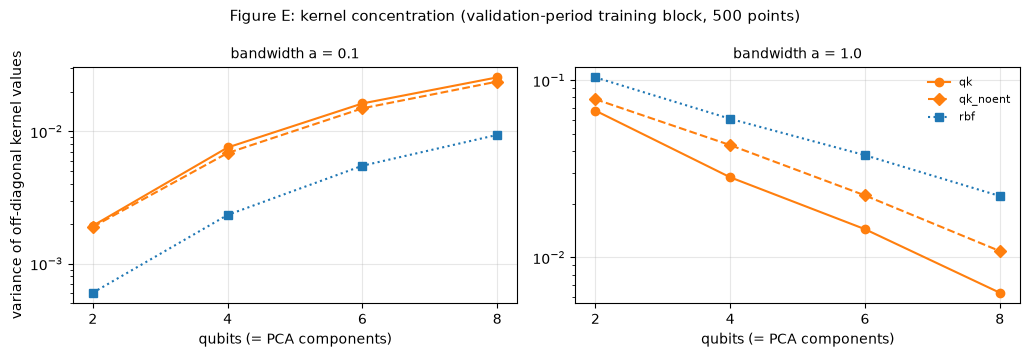

In [8]:
# Cell 8: kernel concentration diagnostic: variance of off-diagonal kernel values vs qubits (500 train points, 1% block)
a_q4 = float(best.filter((pl.col("kind") == "qk") & (pl.col("n_qubits") == 4) & (pl.col("fraction") == 0.01))["scale"][0])
conc = []
for a in sorted({a_q4, 1.0}):
    conc += QK.concentration(data, KINDS, (2, 4, 6, 8), a)
conc = pl.DataFrame(conc)
conc.write_csv(REP / "qkernel_concentration_val.csv")
print(conc.with_columns(pl.col("mean_offdiag").round(4), pl.col("var_offdiag").map_elements(lambda v: f"{v:.3e}", return_dtype=pl.Utf8)))
fig, axes = plt.subplots(1, conc["scale"].n_unique(), figsize=(5.2 * conc["scale"].n_unique(), 3.6), squeeze=False)
style = {"qk": ("tab:orange", "-", "o"), "qk_noent": ("tab:orange", "--", "D"), "rbf": ("tab:blue", ":", "s")}
for ax, a in zip(axes[0], sorted(conc["scale"].unique().to_list())):
    for k in KINDS:
        d = conc.filter((pl.col("kind") == k) & (pl.col("scale") == a)).sort("n_qubits")
        c, ls, mk = style[k]
        ax.plot(d["n_qubits"], d["var_offdiag"], color=c, ls=ls, marker=mk, label=k)
    ax.set_yscale("log"); ax.set_xticks([2, 4, 6, 8]); ax.set_xlabel("qubits (= PCA components)")
    ax.set_title(f"bandwidth a = {a}", fontsize=10); ax.grid(alpha=0.3)
axes[0][0].set_ylabel("variance of off-diagonal kernel values")
axes[0][-1].legend(frameon=False, fontsize=8)
fig.suptitle("Figure E: kernel concentration (validation-period training block, 500 points)", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "E_kernel_concentration.png", dpi=150)
plt.show()
SUMMARY["concentration"] = conc.to_dicts()

In [9]:
# Cell 9: summary
(REP / "week6_qkernel.json").write_text(json.dumps(SUMMARY, indent=1, default=str))
print("written:", REP / "week6_qkernel.json", "|", FIG / "E_kernel_concentration.png")

written: /Users/aryaneuse/Desktop/Uni Project/datacenter-power-forecasting/reports/week6/week6_qkernel.json | /Users/aryaneuse/Desktop/Uni Project/datacenter-power-forecasting/reports/figures/week6/E_kernel_concentration.png


In [11]:
# Cell 10: export outputs (save the notebook first with Cmd+S, then run this cell)
%run ../src/tools/nb_outputs_to_md.py 22b_week6_quantum_kernel.ipynb

written 22b_week6_quantum_kernel_outputs.md | code cells 11 | figures 1 in 22b_week6_quantum_kernel_outputs_figures
